<a href="https://colab.research.google.com/github/claraleorencia/PDS-CLARA/blob/main/REGRESI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kota Jayapura: 11 observasi (2014-2024)

MODEL 2D: PE = b0 + b1*bm_ekonomi
            Koefisien  Std.Error  t-hitung  p-value
Intersep       8.6549     1.0457    8.2769    0.000
bm_ekonomi    -0.0154     0.0051   -2.9966    0.015

R2 = 0.4994 | Adj R2 = 0.4438 | RMSE = 1.1625
F = 8.9798 (p = 0.0150) | df residual = 9

MODEL 2D: PE = b0 + b1*bm_infrastruktur
                  Koefisien  Std.Error  t-hitung  p-value
Intersep             3.3009     0.9141    3.6110   0.0057
bm_infrastruktur     0.0136     0.0046    2.9559   0.0161

R2 = 0.4926 | Adj R2 = 0.4362 | RMSE = 1.1704
F = 8.7374 (p = 0.0161) | df residual = 9

MODEL 3D: PE = b0 + b1*bm_ekonomi + b2*bm_infrastruktur
                  Koefisien  Std.Error  t-hitung  p-value
Intersep             6.0770     1.6770    3.6237   0.0067
bm_ekonomi          -0.0102     0.0054   -1.8880   0.0957
bm_infrastruktur     0.0089     0.0048    1.8462   0.1021

R2 = 0.6490 | Adj R2 = 0.5612 | RMSE = 0.9735
F = 7.3958 (p = 0.0152) | df residual = 

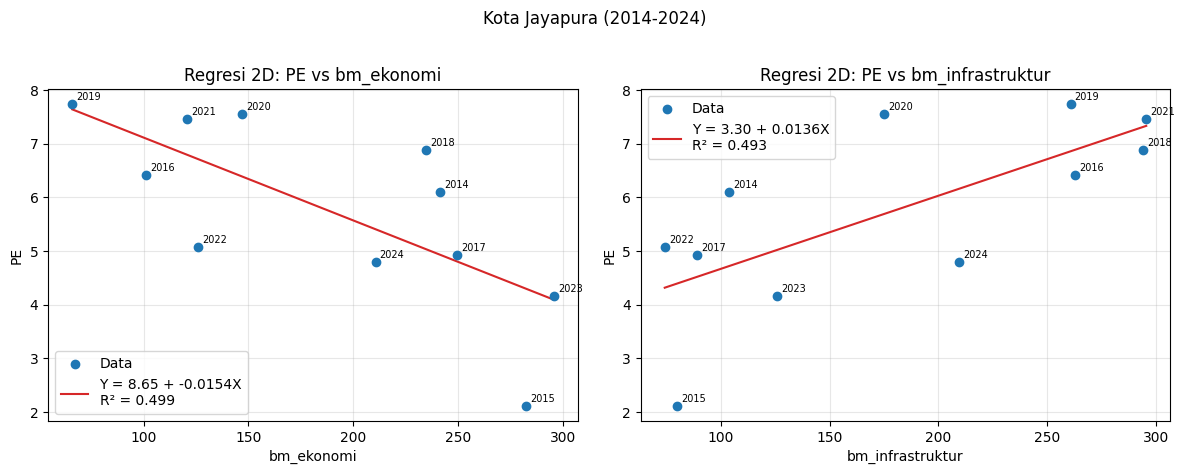

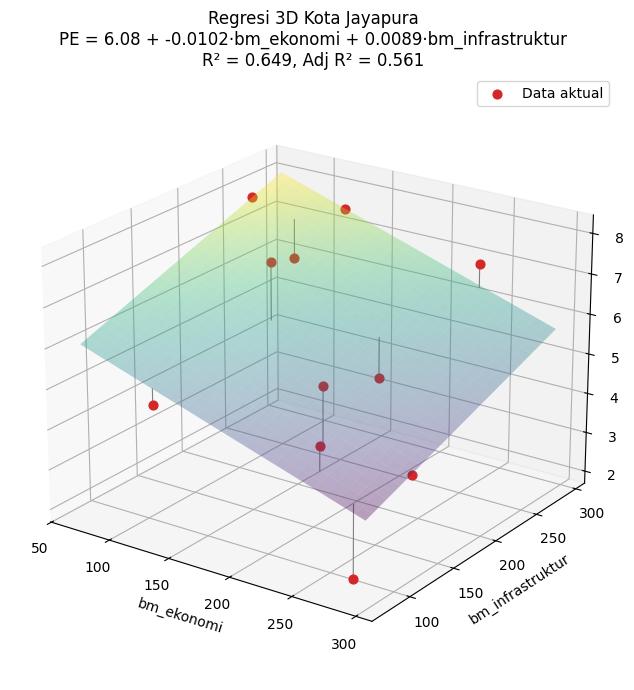

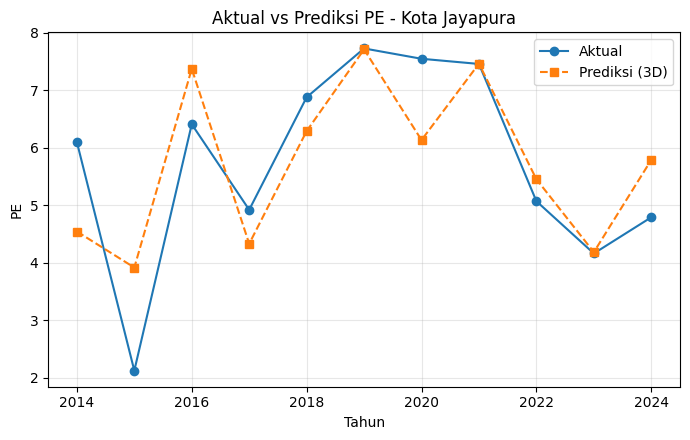

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# ========= PENGATURAN (silakan ganti) =========
FILE   = "dataset_fiskal_97_hipoFull__1_.csv"
KOTA   = "Kota Jayapura"
Y_VAR  = "PE"                 # variabel terikat
X1_VAR = "bm_ekonomi"         # variabel bebas 1
X2_VAR = "bm_infrastruktur"   # variabel bebas 2
# ==============================================

FILE = "/content/dataset_fiskal_97_hipoFull (1).csv"
df = pd.read_csv(FILE)
d = df[df["Kota"] == KOTA].sort_values("Tahun").reset_index(drop=True)
print(f"{KOTA}: {len(d)} observasi ({d.Tahun.min()}-{d.Tahun.max()})\n")


_trap = getattr(np, 'trapezoid', None) or getattr(np, 'trapz')


def t_cdf(t, df_):
    """CDF distribusi t (numerik, tanpa scipy)."""
    x = np.linspace(-abs(t), abs(t), 20001)
    pdf = (np.exp(_lgamma((df_ + 1) / 2) - _lgamma(df_ / 2))
           / np.sqrt(df_ * np.pi) * (1 + x**2 / df_) ** (-(df_ + 1) / 2))
    return _trap(pdf, x)  # peluang |T| < |t|


def _lgamma(z):
    from math import lgamma
    return lgamma(z)


def p_t(t, df_):
    return 1 - t_cdf(t, df_)  # p-value dua sisi


def p_f(F, d1, d2):
    """p-value uji F via integrasi numerik densitas F (substitusi x=u^2
    agar singularitas di x=0 hilang)."""
    from math import lgamma
    u = np.linspace(1e-9, np.sqrt(F), 200001)
    x = u**2
    logc = (lgamma((d1 + d2) / 2) - lgamma(d1 / 2) - lgamma(d2 / 2)
            + (d1 / 2) * np.log(d1 / d2))
    pdf = np.exp(logc + (d1 / 2 - 1) * np.log(x)
                 - ((d1 + d2) / 2) * np.log(1 + d1 * x / d2))
    return float(min(1.0, max(0.0, 1 - _trap(pdf * 2 * u, u))))


def ols(X, y, names):
    """OLS: beta = (X'X)^-1 X'y, lengkap dengan R2, uji t, uji F."""
    n, k = X.shape                      # k termasuk intersep
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    yhat = X @ beta
    resid = y - yhat
    sse = resid @ resid
    sst = ((y - y.mean()) ** 2).sum()
    ssr = sst - sse
    dfe = n - k
    mse = sse / dfe
    se = np.sqrt(np.diag(XtX_inv) * mse)
    tval = beta / se
    pval = np.array([p_t(t, dfe) for t in tval])
    r2 = 1 - sse / sst
    adj = 1 - (1 - r2) * (n - 1) / dfe
    F = (ssr / (k - 1)) / mse
    res = pd.DataFrame({"Koefisien": beta, "Std.Error": se,
                        "t-hitung": tval, "p-value": pval}, index=names)
    return dict(beta=beta, yhat=yhat, resid=resid, r2=r2, adj=adj, F=F,
                pF=p_f(F, k - 1, dfe), rmse=np.sqrt(sse / n), dfe=dfe, table=res)


def report(title, r):
    print("=" * 62)
    print(title)
    print("=" * 62)
    print(r["table"].round(4).to_string())
    print(f"\nR2 = {r['r2']:.4f} | Adj R2 = {r['adj']:.4f} | RMSE = {r['rmse']:.4f}")
    print(f"F = {r['F']:.4f} (p = {r['pF']:.4f}) | df residual = {r['dfe']}\n")


y = d[Y_VAR].to_numpy(float)
x1 = d[X1_VAR].to_numpy(float)
x2 = d[X2_VAR].to_numpy(float)
ones = np.ones_like(y)

# ---------------- MODEL 2D ----------------
res2d = {}
for xv, x in [(X1_VAR, x1), (X2_VAR, x2)]:
    r = ols(np.column_stack([ones, x]), y, ["Intersep", xv])
    res2d[xv] = r
    report(f"MODEL 2D: {Y_VAR} = b0 + b1*{xv}", r)

# ---------------- MODEL 3D ----------------
res3d = ols(np.column_stack([ones, x1, x2]), y, ["Intersep", X1_VAR, X2_VAR])
report(f"MODEL 3D: {Y_VAR} = b0 + b1*{X1_VAR} + b2*{X2_VAR}", res3d)

# Korelasi & multikolinearitas
print("Matriks korelasi:")
print(d[[Y_VAR, X1_VAR, X2_VAR]].corr().round(3).to_string())
r12 = np.corrcoef(x1, x2)[0, 1]
print(f"VIF (2 variabel bebas) = {1 / (1 - r12**2):.3f}\n")

# Tabel aktual vs prediksi
out = d[["Tahun", Y_VAR, X1_VAR, X2_VAR]].copy()
out["Prediksi_3D"] = res3d["yhat"]
out["Residual_3D"] = res3d["resid"]
out.round(4).to_csv("hasil_regresi_jayapura.csv", index=False)
print(out.round(3).to_string(index=False))

# ---------------- GRAFIK 2D ----------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (xv, x) in zip(axes, [(X1_VAR, x1), (X2_VAR, x2)]):
    r = res2d[xv]
    b0, b1 = r["beta"]
    xs = np.linspace(x.min(), x.max(), 100)
    ax.scatter(x, y, color="tab:blue", zorder=3, label="Data")
    for t, xi, yi in zip(d.Tahun, x, y):
        ax.annotate(str(t), (xi, yi), fontsize=7, xytext=(3, 3),
                    textcoords="offset points")
    ax.plot(xs, b0 + b1 * xs, color="tab:red",
            label=f"Y = {b0:.2f} + {b1:.4f}X\nR² = {r['r2']:.3f}")
    ax.set_xlabel(xv); ax.set_ylabel(Y_VAR)
    ax.set_title(f"Regresi 2D: {Y_VAR} vs {xv}")
    ax.grid(alpha=.3); ax.legend()
plt.suptitle(f"{KOTA} (2014-2024)", y=1.02)
plt.tight_layout()
plt.savefig("regresi_2D_jayapura.png", dpi=200, bbox_inches="tight")

# ---------------- GRAFIK 3D ----------------
b0, b1, b2 = res3d["beta"]
g1 = np.linspace(x1.min(), x1.max(), 30)
g2 = np.linspace(x2.min(), x2.max(), 30)
G1, G2 = np.meshgrid(g1, g2)
Z = b0 + b1 * G1 + b2 * G2

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(G1, G2, Z, alpha=.35, cmap="viridis", edgecolor="none")
ax.scatter(x1, x2, y, color="tab:red", s=40, depthshade=False, label="Data aktual")
for xi, zi, yi, yh in zip(x1, x2, y, res3d["yhat"]):  # garis residual
    ax.plot([xi, xi], [zi, zi], [yi, yh], color="gray", lw=.8)
ax.set_xlabel(X1_VAR); ax.set_ylabel(X2_VAR); ax.set_zlabel(Y_VAR)
ax.set_title(f"Regresi 3D {KOTA}\n{Y_VAR} = {b0:.2f} + {b1:.4f}·{X1_VAR} + {b2:.4f}·{X2_VAR}"
             f"\nR² = {res3d['r2']:.3f}, Adj R² = {res3d['adj']:.3f}")
ax.view_init(elev=22, azim=-55)
ax.legend()
plt.tight_layout()
plt.savefig("regresi_3D_jayapura.png", dpi=200)

# ---------------- AKTUAL vs PREDIKSI ----------------
plt.figure(figsize=(7, 4.5))
plt.plot(d.Tahun, y, "o-", label="Aktual")
plt.plot(d.Tahun, res3d["yhat"], "s--", label="Prediksi (3D)")
plt.xlabel("Tahun"); plt.ylabel(Y_VAR); plt.grid(alpha=.3); plt.legend()
plt.title(f"Aktual vs Prediksi {Y_VAR} - {KOTA}")
plt.tight_layout()
plt.savefig("aktual_vs_prediksi_jayapura.png", dpi=200)
print("\nSelesai: grafik & hasil_regresi_jayapura.csv tersimpan.")
